# Sentiment distribution and time series

Original file name: `Twitter Sentiment Visualisation.ipynb`

**Runs from the data committed in this repository** (`data/derived/`, `data/prices/`, `data/tweet_counts/`, `data/annotation/`). Environment: see `requirements.txt` (Python 3.11, pandas 1.5.3). Outputs that displayed tweet text were cleared.

In [1]:
!pip install -q seaborn

In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import scipy.stats
from pandas. plotting import scatter_matrix
from matplotlib import pyplot
import seaborn as sns
from pandas.plotting import lag_plot, autocorrelation_plot

In [3]:
plt.style.use('ggplot')
plt.rcParams["figure.figsize"] = [16, 8]

# Load dataset
tdf = pd.read_csv('../data/derived/twitter_sentiment_scores_2021.csv', skipinitialspace=True)
tdf['timestamp'] = pd.to_datetime(tdf['timestamp'])
tdf

In [4]:
# Convert the timestamp column to datetime
tdf['timestamp'] = tdf['timestamp'].dt.tz_localize(None)
tdf['month'] = tdf['timestamp'].dt.to_period('M')

In [5]:
# Group by month and sentiment and count the occurrences of each sentiment
sentiment_counts = tdf.groupby(['month', 'Sentiment']).size().unstack().fillna(0)

# Calculate the percentages
sentiment_percentages = sentiment_counts.divide(sentiment_counts.sum(axis=1), axis=0) * 100

# Pie Chart

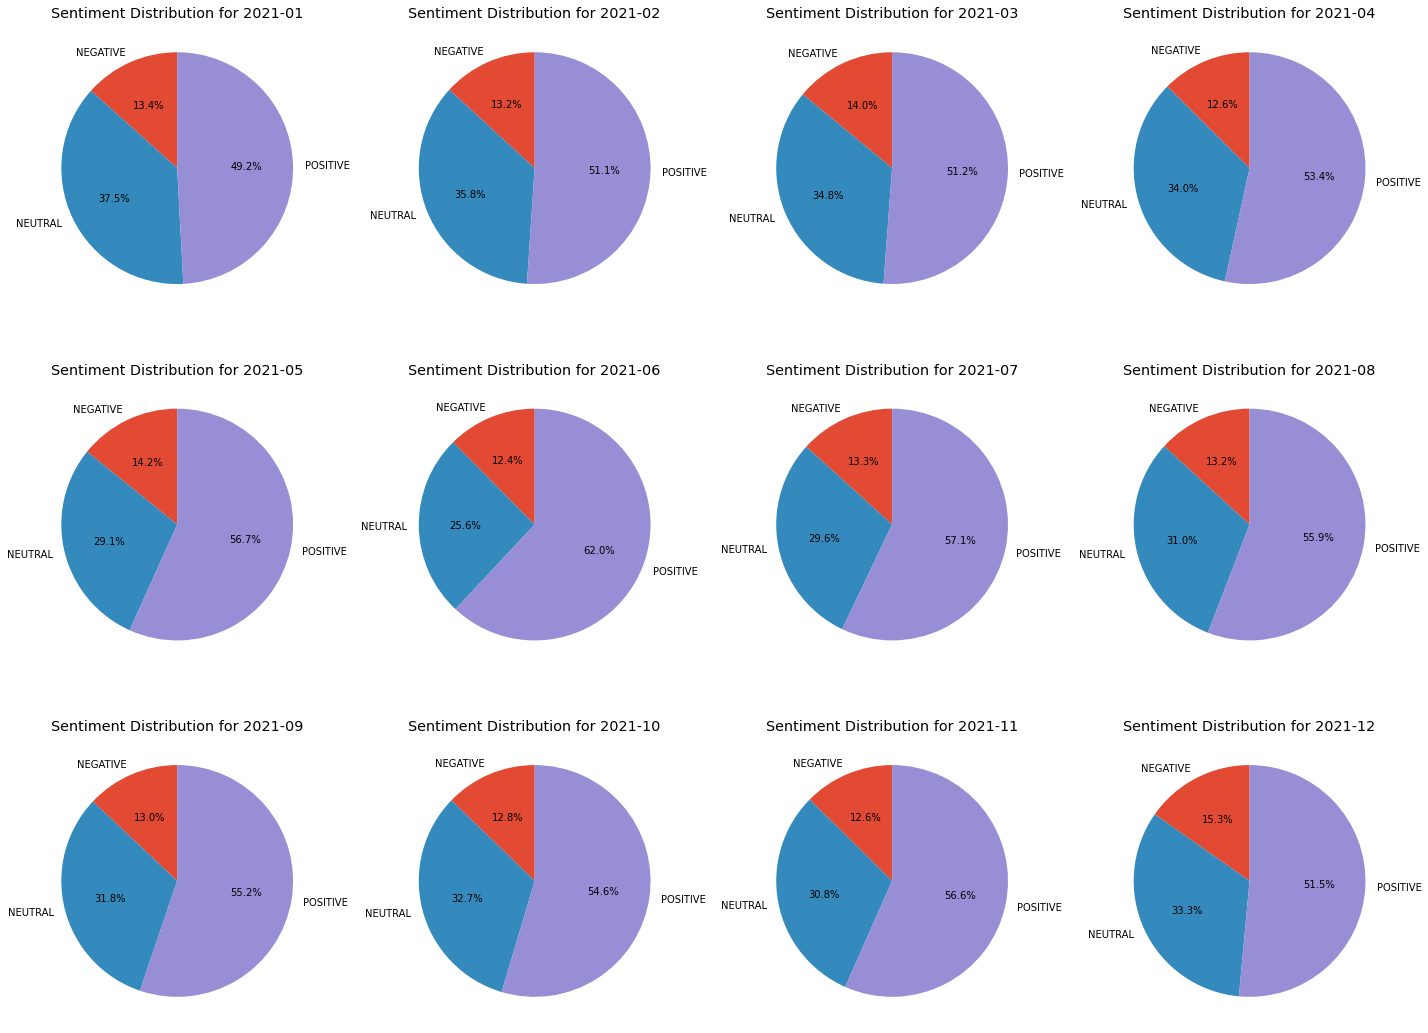

In [6]:
# Create a grid layout for the pie charts: 3 rows x 4 columns
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 15))
axes = axes.flatten()

for i, month in enumerate(sentiment_percentages.index):
    axes[i].pie(sentiment_percentages.loc[month], labels=sentiment_percentages.columns, 
                autopct='%1.1f%%', startangle=90)
    axes[i].set_title(f"Sentiment Distribution for {month}")

plt.tight_layout()
plt.show()

# Histogram Plot

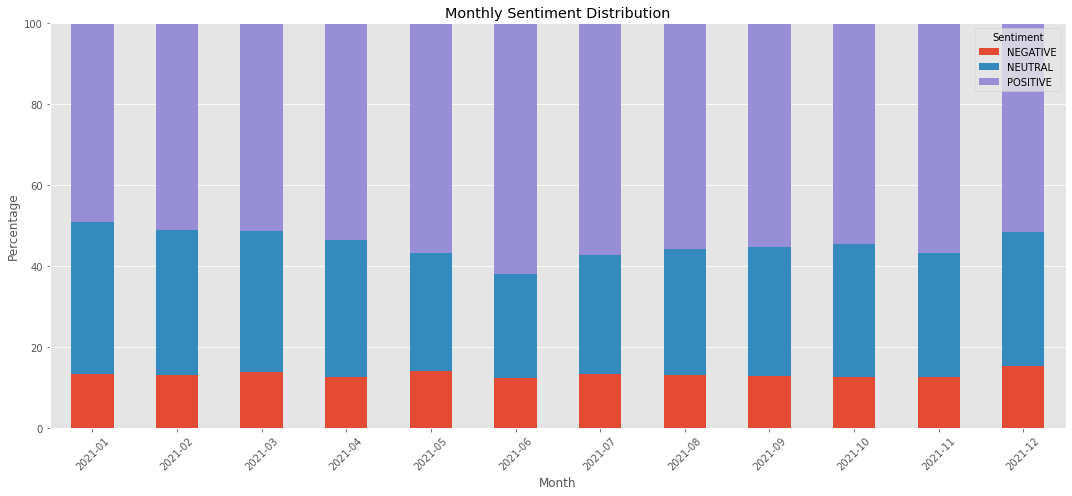

In [7]:
# Plot stacked histogram/bar chart for all months
fig, ax = plt.subplots(figsize=(15, 7))

sentiment_percentages.plot(kind='bar', stacked=True, ax=ax)
ax.set_title("Monthly Sentiment Distribution")
ax.set_ylabel("Percentage")
ax.set_xlabel("Month")
ax.set_ylim(0, 100)
ax.legend(title="Sentiment")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Box Plot

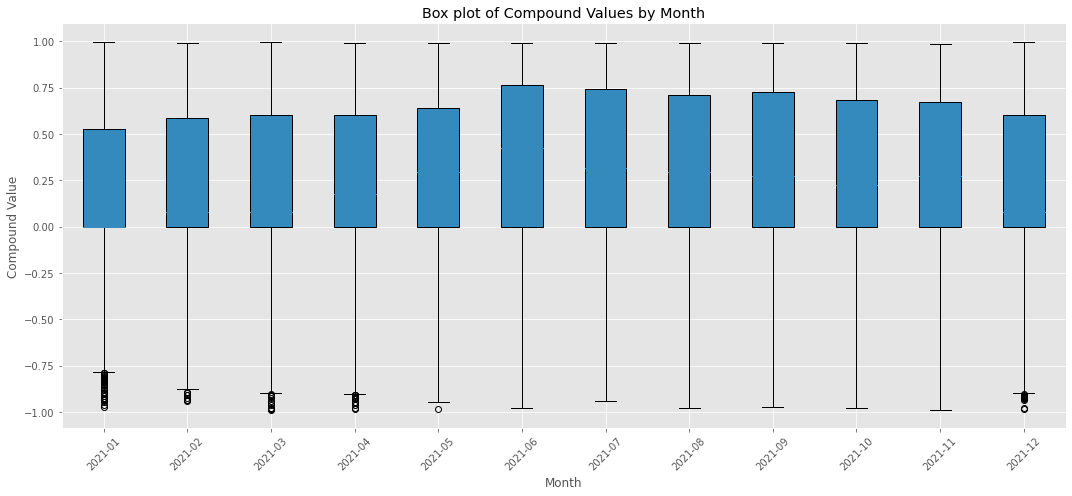

In [8]:
# Group the data by month and get the compound values
compound_values = tdf.groupby('month')['Compound'].apply(list)

# Plot boxplot for each month based on compound values
plt.figure(figsize=(15,7))
plt.boxplot(compound_values, vert=True, patch_artist=True, labels=compound_values.index)
plt.title('Box plot of Compound Values by Month')
plt.ylabel('Compound Value')
plt.xlabel('Month')
plt.xticks(rotation=45)
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

# Table

In [9]:
# Group by month and sentiment to compute counts
pivot_table = tdf.groupby(['month', 'Sentiment']).size().reset_index(name='Counts')

# Pivot the table to have sentiments as columns
pivot_table = pivot_table.pivot(index='month', columns='Sentiment', values='Counts')

# Convert the counts to percentages
pivot_table_percentage = (pivot_table.T / pivot_table.sum(axis=1)).T * 100

# Display the pivot table
pivot_table_percentage

Sentiment,NEGATIVE,NEUTRAL,POSITIVE
month,,,
2021-01,13.350068,37.494295,49.155637
2021-02,13.179050,35.761267,51.059683
2021-03,14.004630,34.814815,51.180556
2021-04,12.565821,34.011489,53.422690
2021-05,14.169858,29.105654,56.724487
2021-06,12.438424,25.591133,61.970443
2021-07,13.278008,29.631438,57.090554
2021-08,13.180516,30.969436,55.850048
2021-09,12.974004,31.814930,55.211066


In [10]:
pivot_table

Sentiment,NEGATIVE,NEUTRAL,POSITIVE
month,,,
2021-01,585,1643,2154
2021-02,541,1468,2096
2021-03,605,1504,2211
2021-04,525,1421,2232
2021-05,629,1292,2518
2021-06,505,1039,2516
2021-07,544,1214,2339
2021-08,552,1297,2339
2021-09,544,1334,2315


In [13]:
daily = tdf.resample('D', on='timestamp').mean(numeric_only=True)
weekly = tdf.resample('W', on='timestamp').mean(numeric_only=True)
monthly = tdf.resample('M', on='timestamp').mean(numeric_only=True)

# Time Series Plot

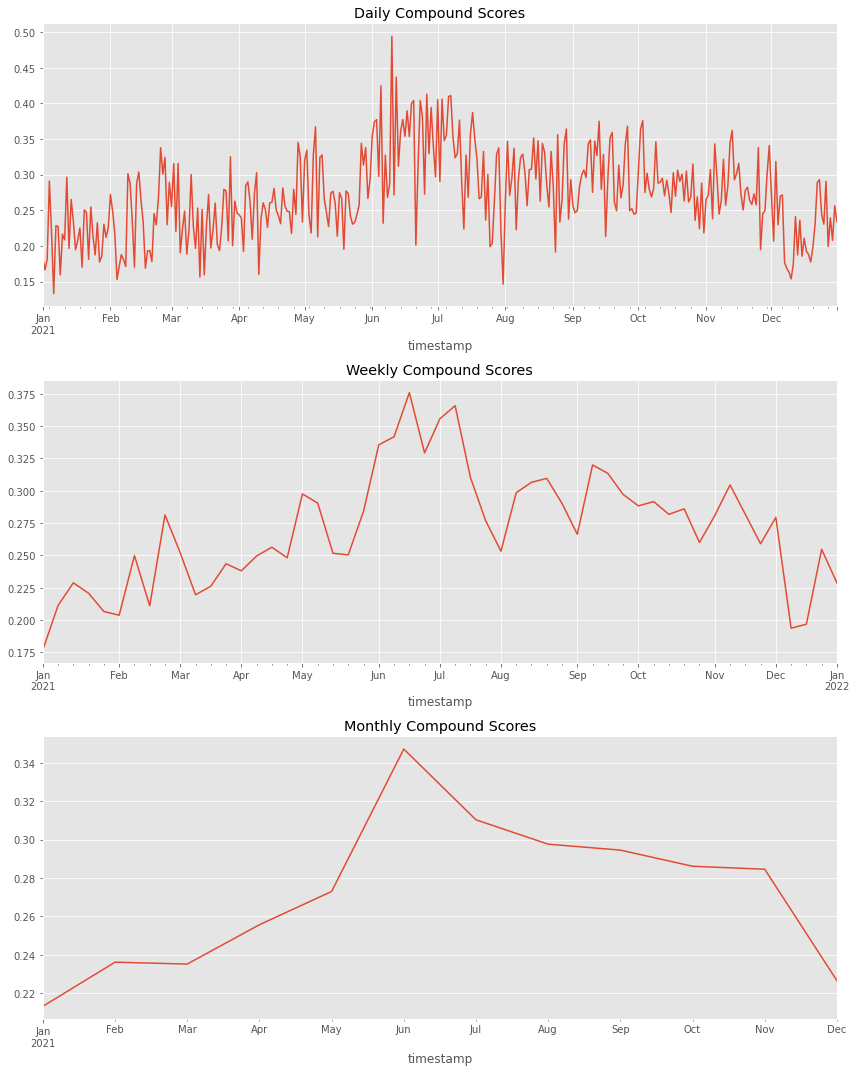

In [14]:
fig, ax = plt.subplots(3, 1, figsize=(12, 15))

daily['Compound'].plot(ax=ax[0], title='Daily Compound Scores')
weekly['Compound'].plot(ax=ax[1], title='Weekly Compound Scores')
monthly['Compound'].plot(ax=ax[2], title='Monthly Compound Scores')
plt.tight_layout()
plt.show()

# KDE Plot

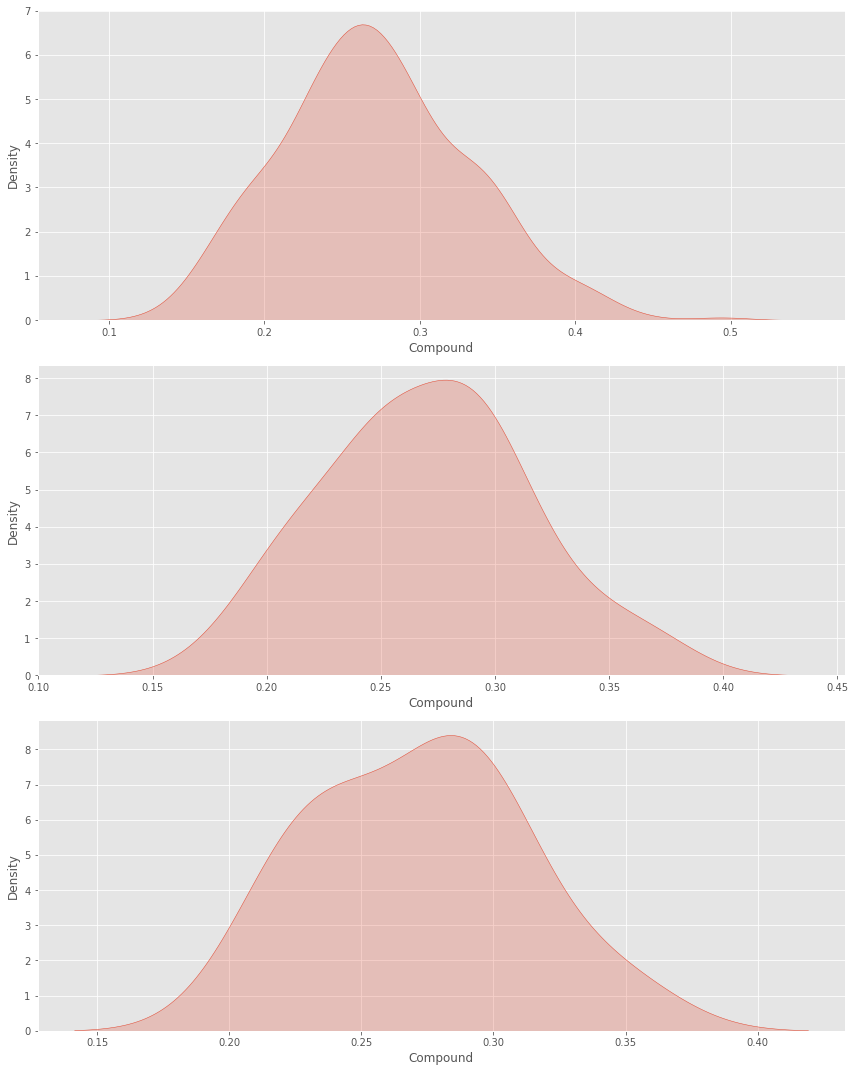

In [16]:
fig, ax = plt.subplots(3, 1, figsize=(12, 15))

sns.kdeplot(daily['Compound'], ax=ax[0], fill=True, label='Daily Compound Scores')
sns.kdeplot(weekly['Compound'], ax=ax[1], fill=True, label='Weekly Compound Scores')
sns.kdeplot(monthly['Compound'], ax=ax[2], fill=True, label='Monthly Compound Scores')
plt.tight_layout()
plt.show()

# Lag Plot

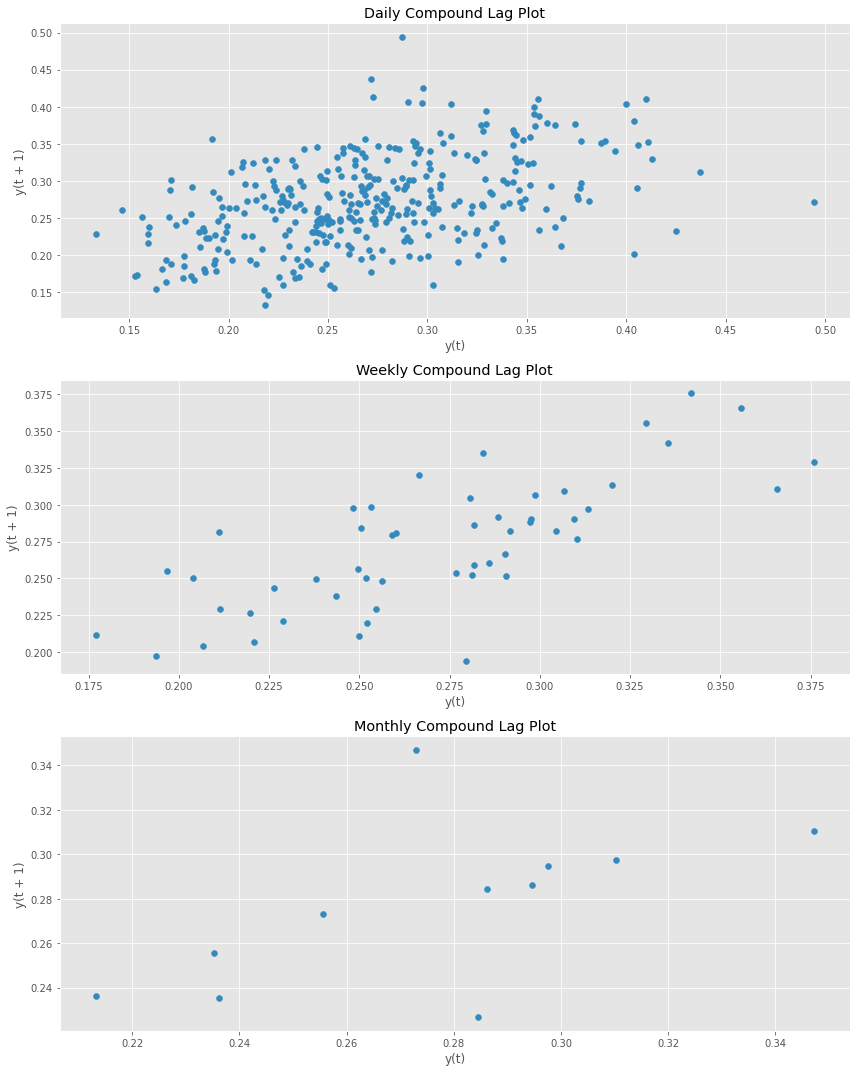

In [17]:
fig, ax = plt.subplots(3, 1, figsize=(12, 15))

lag_plot(daily['Compound'], ax=ax[0])
ax[0].set_title('Daily Compound Lag Plot')
lag_plot(weekly['Compound'], ax=ax[1])
ax[1].set_title('Weekly Compound Lag Plot')
lag_plot(monthly['Compound'], ax=ax[2])
ax[2].set_title('Monthly Compound Lag Plot')
plt.tight_layout()
plt.show()

# Autocorrelation Plot

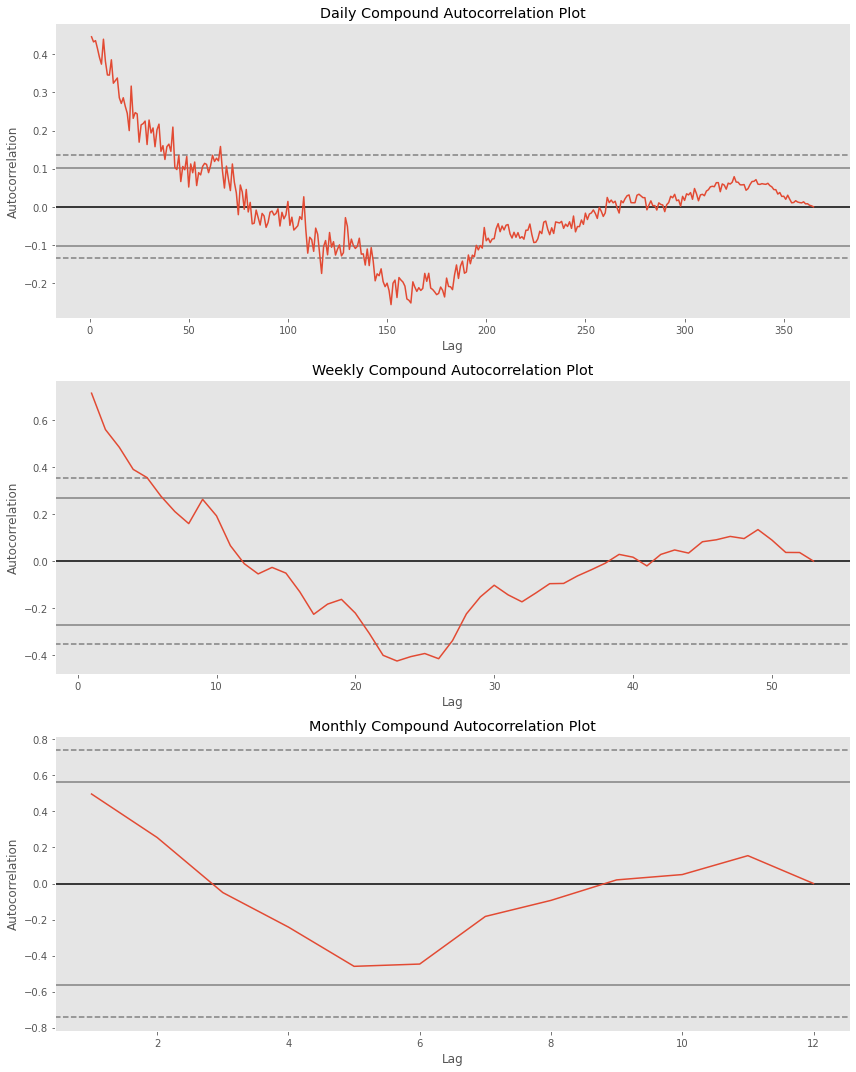

In [18]:
fig, ax = plt.subplots(3, 1, figsize=(12, 15))

autocorrelation_plot(daily['Compound'], ax=ax[0])
ax[0].set_title('Daily Compound Autocorrelation Plot')
autocorrelation_plot(weekly['Compound'], ax=ax[1])
ax[1].set_title('Weekly Compound Autocorrelation Plot')
autocorrelation_plot(monthly['Compound'], ax=ax[2])
ax[2].set_title('Monthly Compound Autocorrelation Plot')
plt.tight_layout()
plt.show()